In [1]:
import torch, time
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(32, 128, 768).cuda()
    linear = torch.nn.Linear(768, 768).cuda()
    start = time.time()
    for _ in range(100): y = linear(x)
    torch.cuda.synchronize()
    print(f"100 linear ops: {time.time()-start:.3f}s (should be well under 1s)")
else:
    print("⚠️ NO GPU — Settings -> Accelerator -> GPU T4 x2/P100, then restart session")

CUDA available: True
GPU: Tesla T4
100 linear ops: 0.221s (should be well under 1s)


In [2]:
import numpy as np, pandas as pd, torch, torch.nn as nn, random, os, json, time
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
import torch.optim as optim
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import pearsonr, ttest_rel, chi2_contingency
from sklearn.metrics import normalized_mutual_info_score
from itertools import product

MODEL_NAME = "/kaggle/input/models/kaydee647/banglabert/pytorch/squadbn/1"
MAX_LEN = 128
BATCH_SIZE = 32
LEARNING_RATE = 2e-5
EPOCHS = 12                  
EARLY_STOP_PATIENCE = 3
GAMMA = 2.0
SENTIMENT_LOSS_WEIGHT = 1.0
EMOTION_LOSS_WEIGHT = 1.5
MAIN_SEED = 42
SEEDS = [42, 123, 7, 99, 2024]   
USE_AMP = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(MAIN_SEED)

Using device: cuda


BanglaBERT Official Normalizer

In [3]:
try:
    import subprocess
    subprocess.run(["pip", "install", "-q", "git+https://github.com/csebuetnlp/normalizer.git"],
                    check=True, timeout=60)
    from normalizer import normalize
    NORMALIZER_AVAILABLE = True
    print("Normalizer loaded.")
except Exception as e:
    NORMALIZER_AVAILABLE = False
    print(f"Normalizer unavailable ({e}) — falling back to raw text.")

def bnorm(text):
    if NORMALIZER_AVAILABLE:
        try: return normalize(text)
        except Exception: return text
    return text

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 2.5 MB/s eta 0:00:00
Normalizer loaded.


In [4]:
RAW_DATA_PATH = "/kaggle/input/datasets/ssbubt/sentiment-and-emotion-detection-dataset/Multilabeled sentiment and emotion detection dataset.xlsx"
CLEAN_DATA_PATH = "/kaggle/working/Multilabeled_sentiment_and_emotion_detection_dataset_deduped.xlsx"

raw_df = pd.read_excel(RAW_DATA_PATH, sheet_name="Sheet1")
raw_df = raw_df.rename(columns={"Text": "text", "Sentiment": "sentiment", "Emotion": "emotion"})
raw_df["text"] = raw_df["text"].astype(str).str.strip()
raw_df["sentiment"] = raw_df["sentiment"].astype(str).str.strip()
raw_df["emotion"] = raw_df["emotion"].astype(str).str.strip()
raw_df = raw_df[raw_df["text"].str.len() > 0]

clean_df = raw_df.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
clean_df.to_excel(CLEAN_DATA_PATH, index=False)
print("Saved:", clean_df.shape)

Saved: (5915, 3)


In [5]:
df = pd.read_excel(CLEAN_DATA_PATH)
print(df.shape)

(5915, 3)


Label Encoding

In [6]:
sentiment_encoder = LabelEncoder(); emotion_encoder = LabelEncoder()
df["sentiment_label"] = sentiment_encoder.fit_transform(df["sentiment"])
df["emotion_label"] = emotion_encoder.fit_transform(df["emotion"])
NUM_SENTIMENT_CLASSES = len(sentiment_encoder.classes_)
NUM_EMOTION_CLASSES = len(emotion_encoder.classes_)
print(sentiment_encoder.classes_, emotion_encoder.classes_)

['Negative' 'Neutral' 'Positive' 'Very Negative' 'Very Positive'] ['Calm' 'Fearful' 'Happy' 'Hateful' 'Religious' 'Sexual' 'Surprised']


In [7]:
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=MAIN_SEED, stratify=df["sentiment_label"])
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=MAIN_SEED, stratify=temp_df["sentiment_label"])
print("Train:", train_df.shape, "Val:", val_df.shape, "Test:", test_df.shape)

Train: (4732, 5) Val: (591, 5) Test: (592, 5)


Joint Startification Audit

In [8]:
for name, split in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"\n{name} emotion distribution:\n", split["emotion"].value_counts(normalize=True).round(3))


Train emotion distribution:
 emotion
Happy        0.281
Calm         0.173
Fearful      0.168
Sexual       0.155
Hateful      0.102
Surprised    0.066
Religious    0.054
Name: proportion, dtype: float64

Val emotion distribution:
 emotion
Happy        0.271
Calm         0.188
Fearful      0.173
Sexual       0.149
Hateful      0.090
Surprised    0.066
Religious    0.064
Name: proportion, dtype: float64

Test emotion distribution:
 emotion
Happy        0.277
Calm         0.174
Sexual       0.174
Fearful      0.157
Hateful      0.103
Surprised    0.079
Religious    0.035
Name: proportion, dtype: float64


Duplicate-Conflict Audit

In [9]:
dup_group_sizes = raw_df.groupby("text").size()
print(f"Total unique texts: {dup_group_sizes.shape[0]}")
print(f"Texts appearing >1x: {(dup_group_sizes > 1).sum()}")
print(f"Duplicate-group size distribution:\n{dup_group_sizes.value_counts().sort_index()}")

conflict_texts = raw_df.groupby("text").filter(
    lambda g: g[["sentiment", "emotion"]].drop_duplicates().shape[0] > 1)
n_conflict_texts = conflict_texts["text"].nunique()
n_conflict_rows = conflict_texts.shape[0]
print(f"\nTexts with conflicting label pairs: {n_conflict_texts}")
print(f"Rows involved: {n_conflict_rows}")
print(f"Conflict rate among duplicated texts: {n_conflict_texts/(dup_group_sizes>1).sum():.1%}")

pd.DataFrame({"metric": ["unique_texts","dup_texts",">1_conflict_texts","conflict_rows"],
              "value": [dup_group_sizes.shape[0], (dup_group_sizes>1).sum(), n_conflict_texts, n_conflict_rows]
             }).to_csv("/kaggle/working/dedup_audit.csv", index=False)

Total unique texts: 5915
Texts appearing >1x: 5915
Duplicate-group size distribution:
4      1227
5       438
6      2111
7       450
8        22
9       442
10        6
11     1144
12       45
13        1
14        1
15        3
16        2
17        2
18       12
20        1
22        5
28        1
36        1
111       1
Name: count, dtype: int64

Texts with conflicting label pairs: 23
Rows involved: 380
Conflict rate among duplicated texts: 0.4%


Association Analysis: TRAIN (primary) vs TEST (verify)

=== PRIMARY: TRAIN partition ===
[TRAIN] n=4732 | chi2=8826.95, df=24, p=0.0000e+00 | V=0.682 | NMI=0.555

=== VERIFY: held-out TEST partition ===
[TEST] n=592 | chi2=1137.20, df=24, p=5.8931e-225 | V=0.688 | NMI=0.565

=== FULL dataset (descriptive, Table I/Fig.2 only) ===
[FULL] n=5915 | chi2=11090.04, df=24, p=0.0000e+00 | V=0.684 | NMI=0.556


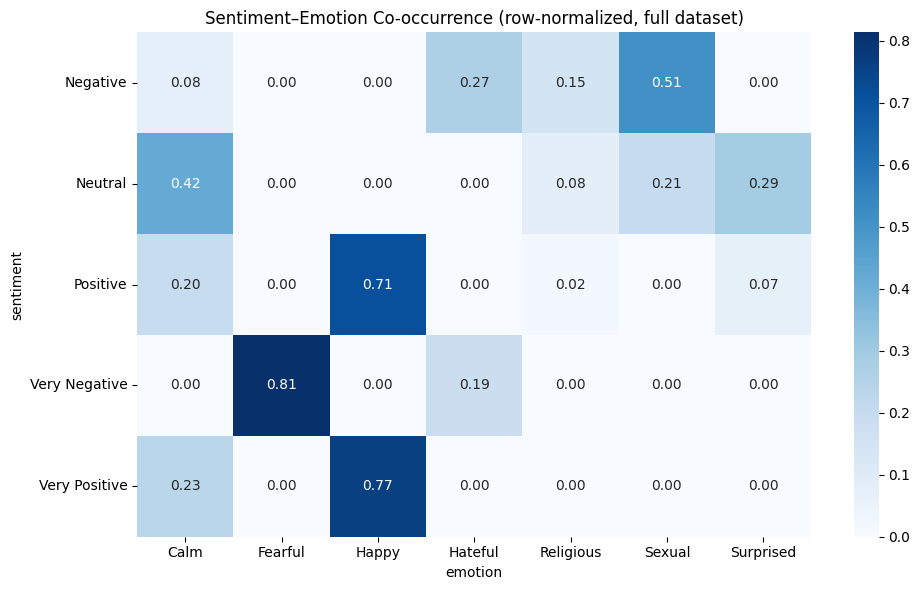

In [10]:
def association_stats(data, label=""):
    contingency = pd.crosstab(data["sentiment"], data["emotion"])
    chi2, p_val, dof, _ = chi2_contingency(contingency)
    n = contingency.sum().sum(); r, k = contingency.shape
    phi2 = chi2 / n
    phi2_c = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    r_c = r - ((r-1)**2)/(n-1); k_c = k - ((k-1)**2)/(n-1)
    cramers_v = np.sqrt(phi2_c / min(k_c-1, r_c-1))
    nmi = normalized_mutual_info_score(data["sentiment"], data["emotion"])
    print(f"[{label}] n={n} | chi2={chi2:.2f}, df={dof}, p={p_val:.4e} | V={cramers_v:.3f} | NMI={nmi:.3f}")
    return {"chi2": chi2, "dof": dof, "p": p_val, "cramers_v": cramers_v, "nmi": nmi}

print("=== PRIMARY: TRAIN partition ===")
train_assoc_stats = association_stats(train_df, "TRAIN")
print("\n=== VERIFY: held-out TEST partition ===")
test_assoc_stats = association_stats(test_df, "TEST")
print("\n=== FULL dataset (descriptive, Table I/Fig.2 only) ===")
full_assoc_stats = association_stats(df, "FULL")

plt.figure(figsize=(10,6))
contingency_full = pd.crosstab(df["sentiment"], df["emotion"])
sns.heatmap(contingency_full.div(contingency_full.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="Blues")
plt.title("Sentiment–Emotion Co-occurrence (row-normalized, full dataset)")
plt.tight_layout(); plt.savefig("/kaggle/working/cooccurrence_heatmap.png", dpi=200); plt.show()

Tokenizer, Dataset Class (Now with Normalizer), DataLoaders

In [11]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, local_files_only=True)

class SentimentEmotionDataset(Dataset):
    def __init__(self, texts, sentiment_labels, emotion_labels, tokenizer, max_len=128):
        self.texts=texts; self.sentiment_labels=sentiment_labels
        self.emotion_labels=emotion_labels; self.tokenizer=tokenizer; self.max_len=max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        text = bnorm(str(self.texts[idx]))
        enc = self.tokenizer(text, truncation=True, padding="max_length", max_length=self.max_len, return_tensors="pt")
        return {"input_ids": enc["input_ids"].squeeze(0), "attention_mask": enc["attention_mask"].squeeze(0),
                "sentiment_label": torch.tensor(self.sentiment_labels[idx], dtype=torch.long),
                "emotion_label": torch.tensor(self.emotion_labels[idx], dtype=torch.long)}

train_dataset = SentimentEmotionDataset(train_df["text"].tolist(), train_df["sentiment_label"].tolist(), train_df["emotion_label"].tolist(), tokenizer, MAX_LEN)
val_dataset = SentimentEmotionDataset(val_df["text"].tolist(), val_df["sentiment_label"].tolist(), val_df["emotion_label"].tolist(), tokenizer, MAX_LEN)
test_dataset = SentimentEmotionDataset(test_df["text"].tolist(), test_df["sentiment_label"].tolist(), test_df["emotion_label"].tolist(), tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

Model Architectures (MTL and STL)

In [12]:
class MultiTaskBanglaBERT(nn.Module):
    def __init__(self, model_name, n_sent, n_emo, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name, local_files_only=True)
        h = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.sentiment_head = nn.Sequential(nn.Linear(h,h//2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(h//2,n_sent))
        self.emotion_head = nn.Sequential(nn.Linear(h,h//2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(h//2,n_emo))
    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(out.last_hidden_state[:,0,:])
        return self.sentiment_head(pooled), self.emotion_head(pooled)

class SingleTaskBanglaBERT(nn.Module):
    def __init__(self, model_name, n_class, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name, local_files_only=True)
        h = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.classifier_head = nn.Sequential(nn.Linear(h,h//2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(h//2,n_class))
    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(out.last_hidden_state[:,0,:])
        return self.classifier_head(pooled)

Focal Loss, Class Weights

In [13]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction="mean"):
        super().__init__(); self.alpha=alpha; self.gamma=gamma; self.reduction=reduction
    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(logits, targets, weight=self.alpha, reduction="none")
        pt = torch.exp(-ce)
        fl = ((1-pt)**self.gamma) * ce
        return fl.mean() if self.reduction=="mean" else (fl.sum() if self.reduction=="sum" else fl)

sentiment_classes = np.unique(train_df["sentiment_label"])
sentiment_weights = compute_class_weight("balanced", classes=sentiment_classes, y=train_df["sentiment_label"])
sentiment_weights_tensor = torch.tensor(sentiment_weights, dtype=torch.float).to(device)
emotion_classes = np.unique(train_df["emotion_label"])
emotion_weights = compute_class_weight("balanced", classes=emotion_classes, y=train_df["emotion_label"])
emotion_weights_tensor = torch.tensor(emotion_weights, dtype=torch.float).to(device)

Training Functions (AMP + Early Stopping)

In [14]:
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

def run_mtl_training(seed, epochs=EPOCHS, save=True, patience=EARLY_STOP_PATIENCE):
    set_seed(seed)
    m = MultiTaskBanglaBERT(MODEL_NAME, NUM_SENTIMENT_CLASSES, NUM_EMOTION_CLASSES).to(device)
    crit_s = FocalLoss(alpha=sentiment_weights_tensor, gamma=GAMMA)
    crit_e = FocalLoss(alpha=emotion_weights_tensor, gamma=GAMMA)
    opt = optim.AdamW(m.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    steps = len(train_loader)*epochs
    sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=int(0.1*steps), num_training_steps=steps)
    best_f1, best_state, no_imp = 0, None, 0
    for epoch in range(epochs):
        m.train()
        for batch in train_loader:
            ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
            sl_=batch["sentiment_label"].to(device); el_=batch["emotion_label"].to(device)
            opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                sl, el = m(ii, am)
                loss = SENTIMENT_LOSS_WEIGHT*crit_s(sl,sl_) + EMOTION_LOSS_WEIGHT*crit_e(el,el_)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=1.0)
            scaler.step(opt); scaler.update(); sched.step()
        m.eval(); vsp,vst,vep,vet=[],[],[],[]
        with torch.no_grad():
            for batch in val_loader:
                ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
                with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)
                vsp.extend(torch.argmax(sl,1).cpu().numpy()); vst.extend(batch["sentiment_label"].numpy())
                vep.extend(torch.argmax(el,1).cpu().numpy()); vet.extend(batch["emotion_label"].numpy())
        combined = (f1_score(vst,vsp,average="macro")+f1_score(vet,vep,average="macro"))/2
        print(f"  [MTL s{seed}] ep{epoch+1}/{epochs} val_f1={combined:.4f}")
        if combined > best_f1:
            best_f1=combined; best_state={k:v.clone() for k,v in m.state_dict().items()}; no_imp=0
        else:
            no_imp+=1
            if no_imp>=patience: print(f"  early stop @ep{epoch+1}"); break
    m.load_state_dict(best_state)
    if save: torch.save(best_state, f"/kaggle/working/mtl_seed{seed}.pt")
    m.eval(); tsp,tst,tep,tet=[],[],[],[]
    with torch.no_grad():
        for batch in test_loader:
            ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
            with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)
            tsp.extend(torch.argmax(sl,1).cpu().numpy()); tst.extend(batch["sentiment_label"].numpy())
            tep.extend(torch.argmax(el,1).cpu().numpy()); tet.extend(batch["emotion_label"].numpy())
    return {"sentiment_f1":f1_score(tst,tsp,average="macro"),"sentiment_acc":accuracy_score(tst,tsp),
            "emotion_f1":f1_score(tet,tep,average="macro"),"emotion_acc":accuracy_score(tet,tep),
            "val_combined_f1":best_f1,"sent_true":tst,"sent_pred":tsp,"emo_true":tet,"emo_pred":tep}

def run_stl_training(seed, task, epochs=EPOCHS, save=True, patience=EARLY_STOP_PATIENCE):
    set_seed(seed)
    n_class = NUM_SENTIMENT_CLASSES if task=="sentiment" else NUM_EMOTION_CLASSES
    lkey = "sentiment_label" if task=="sentiment" else "emotion_label"
    w = sentiment_weights_tensor if task=="sentiment" else emotion_weights_tensor
    m = SingleTaskBanglaBERT(MODEL_NAME, n_class).to(device)
    crit = FocalLoss(alpha=w, gamma=GAMMA)
    opt = optim.AdamW(m.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    steps = len(train_loader)*epochs
    sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=int(0.1*steps), num_training_steps=steps)
    best_f1, best_state, no_imp = 0, None, 0
    for epoch in range(epochs):
        m.train()
        for batch in train_loader:
            ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device); y=batch[lkey].to(device)
            opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = m(ii, am); loss = crit(logits, y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=1.0)
            scaler.step(opt); scaler.update(); sched.step()
        m.eval(); vp,vt=[],[]
        with torch.no_grad():
            for batch in val_loader:
                ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
                with torch.cuda.amp.autocast(enabled=USE_AMP): logits = m(ii, am)
                vp.extend(torch.argmax(logits,1).cpu().numpy()); vt.extend(batch[lkey].numpy())
        val_f1 = f1_score(vt,vp,average="macro")
        print(f"  [STL-{task} s{seed}] ep{epoch+1}/{epochs} val_f1={val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1=val_f1; best_state={k:v.clone() for k,v in m.state_dict().items()}; no_imp=0
        else:
            no_imp+=1
            if no_imp>=patience: print(f"  early stop @ep{epoch+1}"); break
    m.load_state_dict(best_state)
    if save: torch.save(best_state, f"/kaggle/working/stl_{task}_seed{seed}.pt")
    m.eval(); tp,tt=[],[]
    with torch.no_grad():
        for batch in test_loader:
            ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
            with torch.cuda.amp.autocast(enabled=USE_AMP): logits = m(ii, am)
            tp.extend(torch.argmax(logits,1).cpu().numpy()); tt.extend(batch[lkey].numpy())
    return {"f1":f1_score(tt,tp,average="macro"),"acc":accuracy_score(tt,tp),"true":tt,"preds":tp}

/tmp/ipykernel_23/2888870210.py:1: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


For deleting previous saved checkpoints

In [15]:
import glob, os
for f in glob.glob("/kaggle/working/mtl_seed*.pt") + \
         glob.glob("/kaggle/working/stl_sentiment_seed*.pt") + \
         glob.glob("/kaggle/working/stl_emotion_seed*.pt") + \
         glob.glob("/kaggle/working/beta_*_done.json"):
    os.remove(f)
    print("Deleted:", f)

Multi-Seed 

In [16]:
def already_done(path): return os.path.exists(path)

all_results = []
per_seed_raw = {}

for seed in SEEDS:
    print(f"\n{'='*50}\nSEED {seed}\n{'='*50}")

    mtl_path = f"/kaggle/working/mtl_seed{seed}.pt"
    if already_done(mtl_path):
        print(f"  MTL seed {seed} checkpoint found — skipping training")
        m = MultiTaskBanglaBERT(MODEL_NAME, NUM_SENTIMENT_CLASSES, NUM_EMOTION_CLASSES).to(device)
        m.load_state_dict(torch.load(mtl_path)); m.eval()
        tsp,tst,tep,tet=[],[],[],[]
        with torch.no_grad():
            for batch in test_loader:
                ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
                with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)
                tsp.extend(torch.argmax(sl,1).cpu().numpy()); tst.extend(batch["sentiment_label"].numpy())
                tep.extend(torch.argmax(el,1).cpu().numpy()); tet.extend(batch["emotion_label"].numpy())
        mtl_res = {"sentiment_f1":f1_score(tst,tsp,average="macro"),"emotion_f1":f1_score(tet,tep,average="macro"),
                   "val_combined_f1":None,"sent_true":tst,"sent_pred":tsp,"emo_true":tet,"emo_pred":tep}
    else:
        mtl_res = run_mtl_training(seed)

    stl_sent_path = f"/kaggle/working/stl_sentiment_seed{seed}.pt"
    if already_done(stl_sent_path):
        print(f"  STL-sentiment seed {seed} checkpoint found — skipping training")
        m = SingleTaskBanglaBERT(MODEL_NAME, NUM_SENTIMENT_CLASSES).to(device)
        m.load_state_dict(torch.load(stl_sent_path)); m.eval()
        tp,tt=[],[]
        with torch.no_grad():
            for batch in test_loader:
                ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
                with torch.cuda.amp.autocast(enabled=USE_AMP): logits = m(ii, am)
                tp.extend(torch.argmax(logits,1).cpu().numpy()); tt.extend(batch["sentiment_label"].numpy())
        stl_sent_res = {"f1":f1_score(tt,tp,average="macro"),"true":tt,"preds":tp}
    else:
        stl_sent_res = run_stl_training(seed, "sentiment")

    stl_emo_path = f"/kaggle/working/stl_emotion_seed{seed}.pt"
    if already_done(stl_emo_path):
        print(f"  STL-emotion seed {seed} checkpoint found — skipping training")
        m = SingleTaskBanglaBERT(MODEL_NAME, NUM_EMOTION_CLASSES).to(device)
        m.load_state_dict(torch.load(stl_emo_path)); m.eval()
        tp,tt=[],[]
        with torch.no_grad():
            for batch in test_loader:
                ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
                with torch.cuda.amp.autocast(enabled=USE_AMP): logits = m(ii, am)
                tp.extend(torch.argmax(logits,1).cpu().numpy()); tt.extend(batch["emotion_label"].numpy())
        stl_emo_res = {"f1":f1_score(tt,tp,average="macro"),"true":tt,"preds":tp}
    else:
        stl_emo_res = run_stl_training(seed, "emotion")

    per_seed_raw[seed] = {"mtl":mtl_res, "stl_sent":stl_sent_res, "stl_emo":stl_emo_res}
    all_results.append({"seed":seed, "mtl_sentiment_f1":mtl_res["sentiment_f1"], "mtl_emotion_f1":mtl_res["emotion_f1"],
                         "stl_sentiment_f1":stl_sent_res["f1"], "stl_emotion_f1":stl_emo_res["f1"]})
    print(f"SEED {seed} DONE")
    pd.DataFrame(all_results).to_csv("/kaggle/working/multi_seed_results.csv", index=False)

multi_run_df = pd.read_csv("/kaggle/working/multi_seed_results.csv")
multi_run_df_sorted = multi_run_df.sort_values("mtl_sentiment_f1").reset_index(drop=True)
REPRESENTATIVE_SEED = int(multi_run_df_sorted.iloc[len(multi_run_df_sorted)//2]["seed"])
print(f"\nRepresentative seed (median): {REPRESENTATIVE_SEED}")
multi_run_df


SEED 42


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraModel LOAD REPORT from: /kaggle/input/models/kaydee647/banglabert/pytorch/squadbn/1
Key               | Status     |  | 
------------------+------------+--+-
qa_outputs.weight | UNEXPECTED |  | 
qa_outputs.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_23/2888870210.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/2888870210.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)


  [MTL s42] ep1/12 val_f1=0.2883


/tmp/ipykernel_23/2888870210.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/2888870210.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)


  [MTL s42] ep2/12 val_f1=0.4874


... (377 outputs left out)

  [STL-emotion s2024] ep12/12 val_f1=0.7203


/tmp/ipykernel_23/2888870210.py:91: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): logits = m(ii, am)


SEED 2024 DONE

Representative seed (median): 2024


,seed,mtl_sentiment_f1,mtl_emotion_f1,stl_sentiment_f1,stl_emotion_f1
0,42,0.646100,0.696546,0.646328,0.695076
1,123,0.637914,0.667069,0.645708,0.687912
2,7,0.635702,0.705984,0.655558,0.693389
3,99,0.649924,0.689963,0.648422,0.686538
4,2024,0.644924,0.682697,0.638361,0.684493


MTL vs STL Joint-Correctness Comparison

In [17]:
def joint_stats(st, sp, et, ep):
    sc = np.array(st)==np.array(sp); ec = np.array(et)==np.array(ep)
    sa, ea = sc.mean(), ec.mean(); exp = sa*ea; act = (sc & ec).mean()
    r, p = pearsonr(sc.astype(int), ec.astype(int))
    return {"sent_acc":sa,"emo_acc":ea,"expected":exp,"actual":act,"lift":act-exp,"r":r,"p":p}

rows=[]
for seed in SEEDS:
    mtl=per_seed_raw[seed]["mtl"]; ss=per_seed_raw[seed]["stl_sent"]; se=per_seed_raw[seed]["stl_emo"]
    mstat = joint_stats(mtl["sent_true"],mtl["sent_pred"],mtl["emo_true"],mtl["emo_pred"])
    sstat = joint_stats(ss["true"],ss["preds"],se["true"],se["preds"])
    rows.append({"seed":seed,"MTL_joint_acc":mstat["actual"],"MTL_r":mstat["r"],
                 "STL_joint_acc":sstat["actual"],"STL_r":sstat["r"]})

joint_comparison_df = pd.DataFrame(rows)
joint_comparison_df.to_csv("/kaggle/working/mtl_vs_stl_joint_comparison.csv", index=False)
print(joint_comparison_df.to_string(index=False))
print(f"\nMean MTL joint_acc={joint_comparison_df['MTL_joint_acc'].mean():.4f}, STL={joint_comparison_df['STL_joint_acc'].mean():.4f}")
print(f"Mean MTL r={joint_comparison_df['MTL_r'].mean():.4f}, STL r={joint_comparison_df['STL_r'].mean():.4f}")

 seed  MTL_joint_acc    MTL_r  STL_joint_acc    STL_r
   42       0.537162 0.316217       0.540541 0.334233
  123       0.523649 0.356983       0.538851 0.348163
    7       0.548986 0.412052       0.545608 0.358868
   99       0.555743 0.410503       0.532095 0.358499
 2024       0.552365 0.428249       0.535473 0.367123

Mean MTL joint_acc=0.5436, STL=0.5385
Mean MTL r=0.3848, STL r=0.3534


Exact Permutation Test + Aggregate Summary

In [18]:
def paired_permutation_test(diffs):
    diffs=np.array(diffs); n=len(diffs); obs=diffs.mean()
    perm = np.array([(diffs*np.array(s)).mean() for s in product([1,-1], repeat=n)])
    return obs, (np.abs(perm)>=abs(obs)).mean()

for mc, sc, name in [("mtl_sentiment_f1","stl_sentiment_f1","Sentiment F1"),("mtl_emotion_f1","stl_emotion_f1","Emotion F1")]:
    diffs = (multi_run_df[mc]-multi_run_df[sc]).values
    obs,p = paired_permutation_test(diffs)
    print(f"{name}: diffs={diffs.round(4).tolist()}, mean={obs:.4f}, exact p={p:.4f}")

diffs_joint = (joint_comparison_df["MTL_joint_acc"]-joint_comparison_df["STL_joint_acc"]).values
obs,p = paired_permutation_test(diffs_joint)
print(f"Joint accuracy diff: {diffs_joint.round(4).tolist()}, mean={obs:.4f}, exact p={p:.4f}")

summary = pd.DataFrame({"Framework":["STL","MTL (ours)"],
    "Sentiment_F1_mean":[multi_run_df["stl_sentiment_f1"].mean(), multi_run_df["mtl_sentiment_f1"].mean()],
    "Sentiment_F1_std":[multi_run_df["stl_sentiment_f1"].std(), multi_run_df["mtl_sentiment_f1"].std()],
    "Emotion_F1_mean":[multi_run_df["stl_emotion_f1"].mean(), multi_run_df["mtl_emotion_f1"].mean()],
    "Emotion_F1_std":[multi_run_df["stl_emotion_f1"].std(), multi_run_df["mtl_emotion_f1"].std()]})
print("\n", summary.to_string(index=False))
summary.to_csv("/kaggle/working/final_multi_seed_summary.csv", index=False)

Sentiment F1: diffs=[-0.0002, -0.0078, -0.0199, 0.0015, 0.0066], mean=-0.0040, exact p=0.5625
Emotion F1: diffs=[0.0015, -0.0208, 0.0126, 0.0034, -0.0018], mean=-0.0010, exact p=0.8750
Joint accuracy diff: [-0.0034, -0.0152, 0.0034, 0.0236, 0.0169], mean=0.0051, exact p=0.5000

  Framework  Sentiment_F1_mean  Sentiment_F1_std  Emotion_F1_mean  Emotion_F1_std
       STL           0.646875          0.006163         0.689481        0.004544
MTL (ours)           0.642913          0.005923         0.688452        0.014710


Representative-Seed Deep Analysis

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraModel LOAD REPORT from: /kaggle/input/models/kaydee647/banglabert/pytorch/squadbn/1
Key               | Status     |  | 
------------------+------------+--+-
qa_outputs.weight | UNEXPECTED |  | 
qa_outputs.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_23/1085996113.py:10: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = model(ii, am)


=== MTL (representative seed=2024, median val F1) — Sentiment ===
               precision    recall  f1-score   support

     Negative       0.78      0.68      0.73       139
      Neutral       0.53      0.58      0.55       107
     Positive       0.62      0.44      0.52       126
Very Negative       0.79      0.85      0.82       121
Very Positive       0.53      0.71      0.61        99

     accuracy                           0.65       592
    macro avg       0.65      0.65      0.64       592
 weighted avg       0.66      0.65      0.65       592

=== MTL (representative seed=2024) — Emotion ===
              precision    recall  f1-score   support

        Calm       0.47      0.54      0.50       103
     Fearful       0.86      0.91      0.89        93
       Happy       0.79      0.76      0.78       164
     Hateful       0.56      0.61      0.58        61
   Religious       0.67      0.67      0.67        21
      Sexual       0.85      0.72      0.78       103
   Surpr

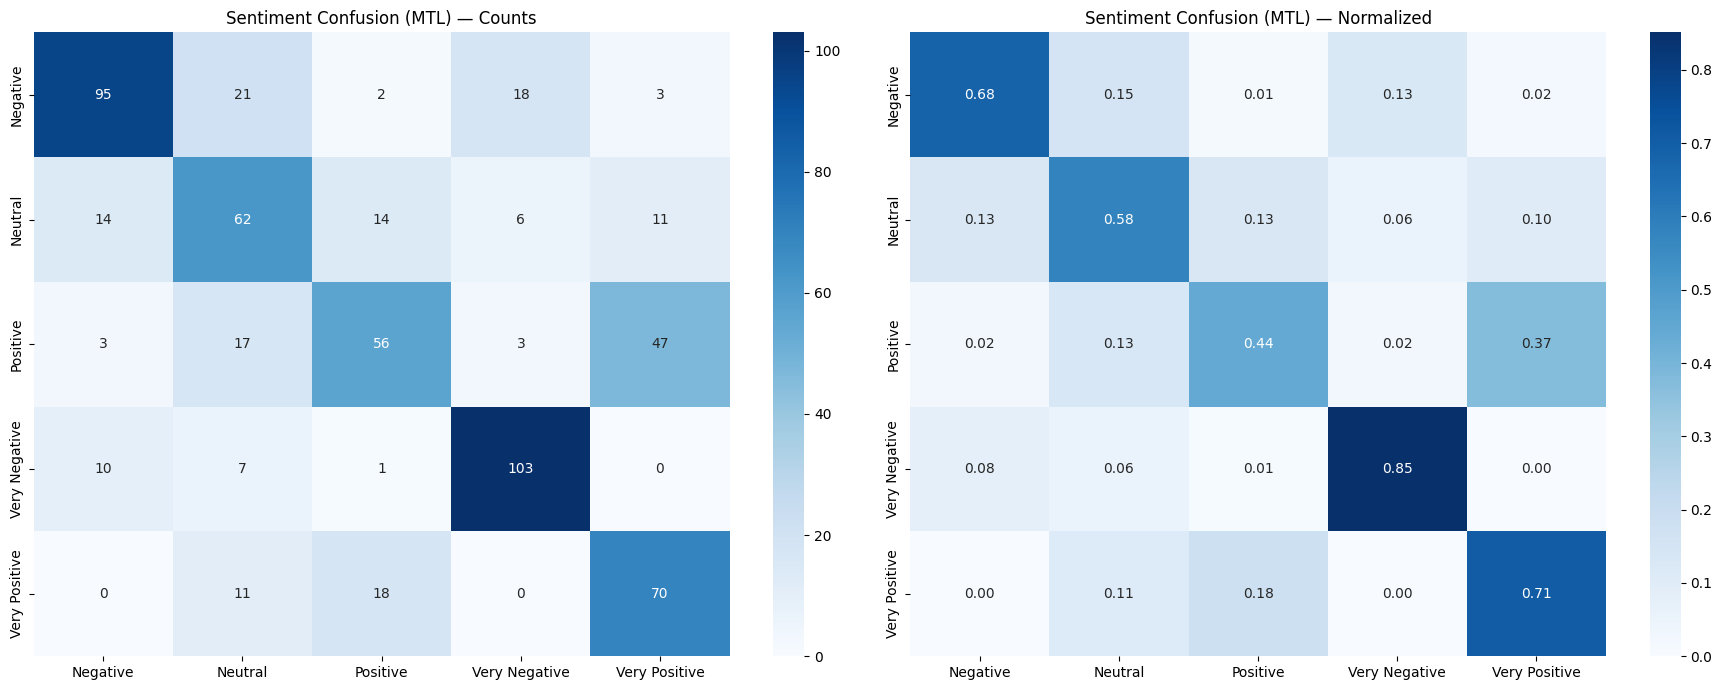

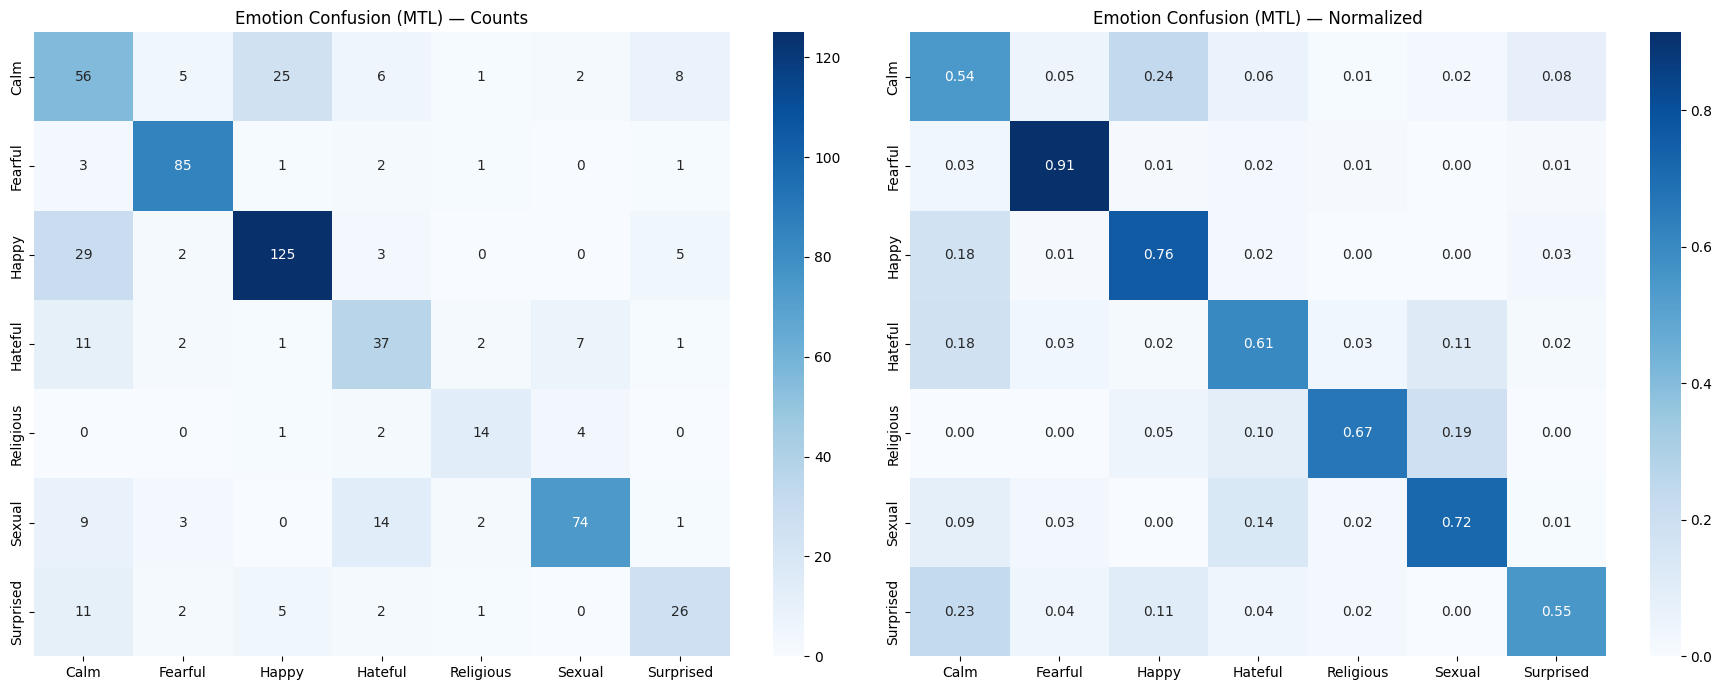


Sent acc=0.6520, Emo acc=0.7044, Expected joint=0.4593, Actual joint=0.5524, lift=+0.0931
Pearson r=0.4282, p=8.4070e-28


/tmp/ipykernel_23/1085996113.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): out = model.encoder(input_ids=ii, attention_mask=am)


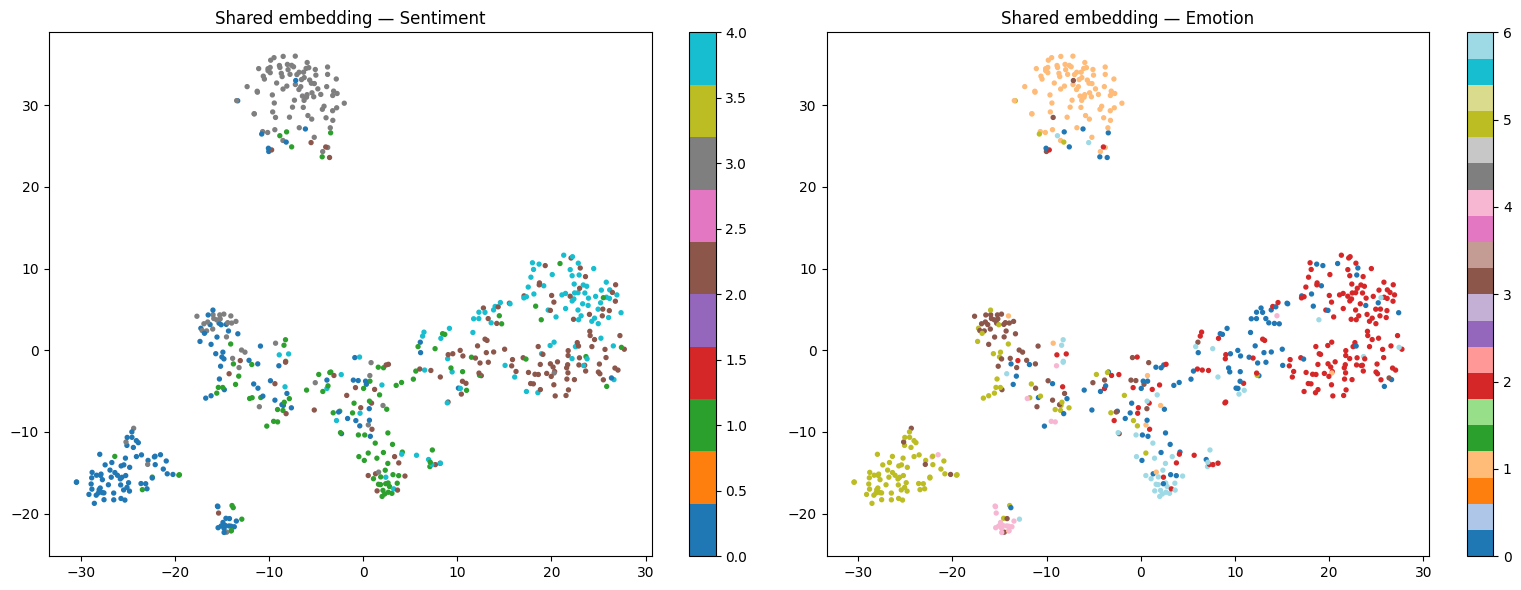

kNN probe -> Emotion acc: 0.6959, Sentiment acc: 0.6452


In [19]:
MAIN_SEED = REPRESENTATIVE_SEED
set_seed(MAIN_SEED)
model = MultiTaskBanglaBERT(MODEL_NAME, NUM_SENTIMENT_CLASSES, NUM_EMOTION_CLASSES).to(device)
model.load_state_dict(torch.load(f"/kaggle/working/mtl_seed{MAIN_SEED}.pt")); model.eval()

all_sentiment_preds, all_sentiment_true, all_emotion_preds, all_emotion_true = [],[],[],[]
with torch.no_grad():
    for batch in test_loader:
        ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
        with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = model(ii, am)
        all_sentiment_preds.extend(torch.argmax(sl,1).cpu().numpy()); all_sentiment_true.extend(batch["sentiment_label"].numpy())
        all_emotion_preds.extend(torch.argmax(el,1).cpu().numpy()); all_emotion_true.extend(batch["emotion_label"].numpy())

print(f"=== MTL (representative seed={MAIN_SEED}, median val F1) — Sentiment ===")
print(classification_report(all_sentiment_true, all_sentiment_preds, target_names=sentiment_encoder.classes_))
print(f"=== MTL (representative seed={MAIN_SEED}) — Emotion ===")
print(classification_report(all_emotion_true, all_emotion_preds, target_names=emotion_encoder.classes_))

def plot_cm(yt, yp, names, title, fn):
    cm = confusion_matrix(yt, yp, labels=range(len(names)))
    fig, ax = plt.subplots(1,2,figsize=(18,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0]); ax[0].set_title(f"{title} — Counts")
    cmn = cm.astype(float)/cm.sum(axis=1,keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[1]); ax[1].set_title(f"{title} — Normalized")
    plt.tight_layout(); plt.savefig(fn, dpi=200); plt.show()

plot_cm(all_sentiment_true, all_sentiment_preds, sentiment_encoder.classes_, "Sentiment Confusion (MTL)", "/kaggle/working/sentiment_confusion.png")
plot_cm(all_emotion_true, all_emotion_preds, emotion_encoder.classes_, "Emotion Confusion (MTL)", "/kaggle/working/emotion_confusion.png")

sc = np.array(all_sentiment_true)==np.array(all_sentiment_preds)
ec = np.array(all_emotion_true)==np.array(all_emotion_preds)
sa, ea = sc.mean(), ec.mean(); exp = sa*ea; act = (sc&ec).mean()
corr, pval = pearsonr(sc.astype(int), ec.astype(int))
print(f"\nSent acc={sa:.4f}, Emo acc={ea:.4f}, Expected joint={exp:.4f}, Actual joint={act:.4f}, lift={act-exp:+.4f}")
print(f"Pearson r={corr:.4f}, p={pval:.4e}")

def get_embeddings(model, loader):
    model.eval(); embs=[]
    with torch.no_grad():
        for batch in loader:
            ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
            with torch.cuda.amp.autocast(enabled=USE_AMP): out = model.encoder(input_ids=ii, attention_mask=am)
            embs.append(out.last_hidden_state[:,0,:].float().cpu().numpy())
    return np.concatenate(embs)

test_embeddings = get_embeddings(model, test_loader)
tsne = TSNE(n_components=2, random_state=MAIN_SEED, perplexity=30)
emb2d = tsne.fit_transform(test_embeddings)
fig, ax = plt.subplots(1,2,figsize=(16,6))
s1=ax[0].scatter(emb2d[:,0],emb2d[:,1],c=all_sentiment_true,cmap="tab10",s=8); plt.colorbar(s1,ax=ax[0]); ax[0].set_title("Shared embedding — Sentiment")
s2=ax[1].scatter(emb2d[:,0],emb2d[:,1],c=all_emotion_true,cmap="tab20",s=8); plt.colorbar(s2,ax=ax[1]); ax[1].set_title("Shared embedding — Emotion")
plt.tight_layout(); plt.savefig("/kaggle/working/tsne_representative.png", dpi=200); plt.show()

knn_emo = cross_val_score(KNeighborsClassifier(n_neighbors=15), test_embeddings, all_emotion_true, cv=5).mean()
knn_sent = cross_val_score(KNeighborsClassifier(n_neighbors=15), test_embeddings, all_sentiment_true, cv=5).mean()
print(f"kNN probe -> Emotion acc: {knn_emo:.4f}, Sentiment acc: {knn_sent:.4f}")

Lean β-Ablation (single seed)

In [20]:
def run_mtl_with_weight(seed, beta, epochs=EPOCHS, patience=EARLY_STOP_PATIENCE):  # epochs=5 -> epochs=EPOCHS (10), patience add kora holo
    set_seed(seed)
    m = MultiTaskBanglaBERT(MODEL_NAME, NUM_SENTIMENT_CLASSES, NUM_EMOTION_CLASSES).to(device)
    crit_s = FocalLoss(alpha=sentiment_weights_tensor, gamma=GAMMA)
    crit_e = FocalLoss(alpha=emotion_weights_tensor, gamma=GAMMA)
    opt = optim.AdamW(m.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    steps = len(train_loader)*epochs
    sched = get_linear_schedule_with_warmup(opt, num_warmup_steps=int(0.1*steps), num_training_steps=steps)
    best_f1, best_state, no_imp = 0, None, 0
    for epoch in range(epochs):
        m.train()
        for batch in train_loader:
            ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
            sl_=batch["sentiment_label"].to(device); el_=batch["emotion_label"].to(device)
            opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                sl, el = m(ii, am); loss = 1.0*crit_s(sl,sl_) + beta*crit_e(el,el_)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(), max_norm=1.0)
            scaler.step(opt); scaler.update(); sched.step()
        m.eval(); vsp,vst,vep,vet=[],[],[],[]
        with torch.no_grad():
            for batch in val_loader:
                ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
                with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)
                vsp.extend(torch.argmax(sl,1).cpu().numpy()); vst.extend(batch["sentiment_label"].numpy())
                vep.extend(torch.argmax(el,1).cpu().numpy()); vet.extend(batch["emotion_label"].numpy())
        combined = (f1_score(vst,vsp,average="macro")+f1_score(vet,vep,average="macro"))/2
        print(f"  [beta={beta}] ep{epoch+1}/{epochs} val_f1={combined:.4f}")
        if combined > best_f1:
            best_f1=combined; best_state={k:v.clone() for k,v in m.state_dict().items()}; no_imp=0
        else:
            no_imp+=1
            if no_imp>=patience: print(f"  early stop @ep{epoch+1}"); break
    m.load_state_dict(best_state); m.eval(); tsp,tst,tep,tet=[],[],[],[]
    with torch.no_grad():
        for batch in test_loader:
            ii=batch["input_ids"].to(device); am=batch["attention_mask"].to(device)
            with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)
            tsp.extend(torch.argmax(sl,1).cpu().numpy()); tst.extend(batch["sentiment_label"].numpy())
            tep.extend(torch.argmax(el,1).cpu().numpy()); tet.extend(batch["emotion_label"].numpy())
    return {"sentiment_f1":f1_score(tst,tsp,average="macro"),"emotion_f1":f1_score(tet,tep,average="macro")}

BETA_CANDIDATES = [1.0, 1.5, 2.0]
beta_results = []
for beta in BETA_CANDIDATES:
    if already_done(f"/kaggle/working/beta_{beta}_done.json"):
        with open(f"/kaggle/working/beta_{beta}_done.json") as f: res = json.load(f)
    else:
        res = run_mtl_with_weight(MAIN_SEED, beta)
        with open(f"/kaggle/working/beta_{beta}_done.json","w") as f: json.dump(res, f)
    beta_results.append({"beta":beta, **res})
    print(f"beta={beta}: Sent F1={res['sentiment_f1']:.4f}, Emo F1={res['emotion_f1']:.4f}")

beta_ablation_df = pd.DataFrame(beta_results)
beta_ablation_df.to_csv("/kaggle/working/beta_ablation_lean.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraModel LOAD REPORT from: /kaggle/input/models/kaydee647/banglabert/pytorch/squadbn/1
Key               | Status     |  | 
------------------+------------+--+-
qa_outputs.weight | UNEXPECTED |  | 
qa_outputs.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_23/559019140.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/559019140.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)


  [beta=1.0] ep1/12 val_f1=0.3315


/tmp/ipykernel_23/559019140.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/559019140.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)


  [beta=1.0] ep2/12 val_f1=0.5499


/tmp/ipykernel_23/559019140.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/559019140.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)


... (71 outputs left out)

/tmp/ipykernel_23/559019140.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_23/559019140.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)


  [beta=2.0] ep12/12 val_f1=0.6604
  early stop @ep12


/tmp/ipykernel_23/559019140.py:39: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP): sl, el = m(ii, am)


beta=2.0: Sent F1=0.5990, Emo F1=0.6823


Efficiency Comparison

In [21]:
def count_params(m): return sum(p.numel() for p in m.parameters())
mtl_params = count_params(model)
stl_sent_params = count_params(SingleTaskBanglaBERT(MODEL_NAME, NUM_SENTIMENT_CLASSES).to(device))
stl_emo_params = count_params(SingleTaskBanglaBERT(MODEL_NAME, NUM_EMOTION_CLASSES).to(device))
stl_total = stl_sent_params + stl_emo_params
print(f"MTL params: {mtl_params:,} | STL total (2 encoders): {stl_total:,} | Reduction: {(1-mtl_params/stl_total)*100:.1f}%")

sample = next(iter(test_loader))
ii = sample["input_ids"].to(device); am = sample["attention_mask"].to(device)
model.eval()
with torch.no_grad():
    for _ in range(5): model(ii, am)
    if device.type=="cuda": torch.cuda.synchronize()
    start=time.time()
    for _ in range(20): model(ii, am)
    if device.type=="cuda": torch.cuda.synchronize()
    mtl_latency = (time.time()-start)/20
print(f"MTL latency: {mtl_latency*1000:.2f} ms (both predictions) | STL-equivalent: ~{2*mtl_latency*1000:.2f} ms (2 passes)")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraModel LOAD REPORT from: /kaggle/input/models/kaydee647/banglabert/pytorch/squadbn/1
Key               | Status     |  | 
------------------+------------+--+-
qa_outputs.weight | UNEXPECTED |  | 
qa_outputs.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraModel LOAD REPORT from: /kaggle/input/models/kaydee647/banglabert/pytorch/squadbn/1
Key               | Status     |  | 
------------------+------------+--+-
qa_outputs.weight | UNEXPECTED |  | 
qa_outputs.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


MTL params: 110,621,964 | STL total (2 encoders): 220,648,716 | Reduction: 49.9%
MTL latency: 252.31 ms (both predictions) | STL-equivalent: ~504.62 ms (2 passes)


In [22]:
final_results = {
    "seeds_used": SEEDS, "representative_seed": REPRESENTATIVE_SEED,
    "representative_seed_rule": "median val combined macro-F1",
    "normalizer_applied": NORMALIZER_AVAILABLE,
    "multi_seed_mtl_sentiment_f1_mean": multi_run_df["mtl_sentiment_f1"].mean(),
    "multi_seed_mtl_emotion_f1_mean": multi_run_df["mtl_emotion_f1"].mean(),
    "mean_mtl_joint_acc": joint_comparison_df["MTL_joint_acc"].mean(),
    "mean_stl_joint_acc": joint_comparison_df["STL_joint_acc"].mean(),
    "mean_mtl_r": joint_comparison_df["MTL_r"].mean(), "mean_stl_r": joint_comparison_df["STL_r"].mean(),
    "joint_acc_repr_seed": act, "pearson_r_repr_seed": corr,
    "n_duplicate_conflict_texts": n_conflict_texts,
    "train_assoc_chi2": train_assoc_stats["chi2"], "train_assoc_v": train_assoc_stats["cramers_v"],
    "mtl_params": mtl_params, "stl_total_params": stl_total,
    "knn_probe_emotion_acc": knn_emo, "knn_probe_sentiment_acc": knn_sent,
}
pd.DataFrame([final_results]).to_csv("/kaggle/working/final_summary_reviewer_response.csv", index=False)
print(json.dumps(final_results, indent=2, default=str))

{
  "seeds_used": [
    42,
    123,
    7,
    99,
    2024
  ],
  "representative_seed": 2024,
  "representative_seed_rule": "median val combined macro-F1",
  "normalizer_applied": true,
  "multi_seed_mtl_sentiment_f1_mean": 0.642912986132265,
  "multi_seed_mtl_emotion_f1_mean": 0.6884520190929126,
  "mean_mtl_joint_acc": 0.543581081081081,
  "mean_stl_joint_acc": 0.5385135135135135,
  "mean_mtl_r": 0.38480083735140447,
  "mean_stl_r": 0.3533773116081377,
  "joint_acc_repr_seed": 0.5523648648648649,
  "pearson_r_repr_seed": 0.4282489127446576,
  "n_duplicate_conflict_texts": 23,
  "train_assoc_chi2": 8826.949626714217,
  "train_assoc_v": 0.6822527461606531,
  "mtl_params": 110621964,
  "stl_total_params": 220648716,
  "knn_probe_emotion_acc": 0.6958980202250392,
  "knn_probe_sentiment_acc": 0.6451502634952286
}
